# Laboratorio 6: Transfer Learning y Fine-Tuning
**CC3092 - Deep Learning y Sistemas Inteligentes** · UVG · 30 septiembre 2026

**Ian Cumes 23236 · Javier Valladares 23045**

## Resumen de resultados
Se completaron 9 configuraciones, 21 épocas de búsqueda y 3 reentrenamientos con 10% de datos.
El mejor F1 macro de test fue **68.60%** con **VGG-16 fine-tuning**.
Todos los resultados son mediciones locales; FLOPs de entrenamiento son estimaciones.
Se trabajó en CPU Intel i9-13900H, sin CUDA. VGG usa 32×32 y la CNN 32×32.
Este entrenamiento de dos o tres épocas por configuración está limitado por el tiempo disponible.

Repositorio: [https://github.com/iancumes/Laboratorio6DeepLearning](https://github.com/iancumes/Laboratorio6DeepLearning)

## 1. Entorno y reproducibilidad
Crear un entorno con Python 3.11, ejecutar `pip install -r requirements.txt` y abrir este notebook.
El notebook contiene las definiciones de la implementación. Por defecto carga los resultados
auditables del repositorio; `REENTRENAR=True` vuelve a ejecutar el pipeline si se eliminan los
resultados anteriores. Las imágenes, caches y checkpoints grandes se generan localmente.
Para iniciar una búsqueda distinta, usar un directorio de artifacts nuevo, porque los IDs
existentes se reutilizan. Para Colab, clonar el repositorio y establecer su raíz como cwd.

In [1]:
"""CIFAR-10: CNN propia, VGG-16 feature extraction y fine-tuning.

No se utiliza test para seleccionar configuraciones. La cache contiene solamente
el forward del prefijo congelado; los bloques descongelados siempre reciben
gradientes y se recalculan en cada minibatch.
"""
from __future__ import annotations
import argparse, copy, gc, hashlib, json, os, platform, random, time
from pathlib import Path
import numpy as np
import pandas as pd
import psutil
import torch
from torch import nn
from torch.nn import functional as F
from torchvision import datasets, models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'src').exists(): ROOT = ROOT.parent
assert (ROOT / 'src/pipeline.py').exists(), 'Abrir notebook desde el repositorio o notebooks/'
ART = ROOT / 'artifacts'
FIG = ART / 'figures'
SEED = 23236
SIZE = 32
IM_MEAN = (0.485, 0.456, 0.406)
IM_STD = (0.229, 0.224, 0.225)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
COLORS = {'cnn':'#147d92', 'fe':'#bc7626', 'ft':'#704aad'}
LABELS = {'cnn':'CNN propia', 'fe':'VGG-16 extractor', 'ft':'VGG-16 fine-tuning'}

## 2. Investigación de transfer learning en PyTorch

| API / concepto | Propósito y parámetros relevantes |
|---|---|
| `torchvision.models.vgg16(weights=VGG16_Weights.IMAGENET1K_V1)` | Carga la arquitectura y los pesos supervisados de ImageNet. `weights=None` inicializa sin pesos; `progress` controla la descarga y `dropout` modifica el clasificador. `DEFAULT` selecciona el mismo conjunto de pesos. |
| `weights.transforms()` | Pipeline de inferencia asociado a esos pesos: resize 256, crop central 224, valores [0,1] y normalización RGB con media (0.485,0.456,0.406), desviación (0.229,0.224,0.225). Aquí se adapta el resize a 32 por presupuesto de CPU, conservando la normalización. |
| `features`, `avgpool`, `classifier` | VGG-16 contiene 13 convoluciones organizadas en cinco bloques. `features` incluye convoluciones, ReLU y max-pooling. `AdaptiveAvgPool2d((7,7))` conserva las dimensiones de entrada del clasificador; los Linear son 25088→4096→4096→1000. Se reemplaza únicamente el último Linear por 4096→10. |
| `requires_grad` | Controla si autograd calcula gradientes para un parámetro. Se congela `features` completo; para FT se activan parámetros desde índice 24 (B5) o 17 (B4+B5). Los 119,586,826 parámetros del clasificador permanecen entrenables. |
| `model.train()` y `model.eval()` | Cambian el comportamiento de dropout y batch normalization. `eval()` por sí solo no desactiva autograd. Train permite regularización; evaluación usa BN estable y dropout desactivado. El prefijo congelado permanece en eval. |
| `torch.no_grad()` | Evita construir el grafo de gradientes durante inferencia y generación de cache. No se usa alrededor del sufijo entrenable de FT. |
| `param_groups` | El optimizador recibe listas con `params`, `lr` y opcionalmente `weight_decay`. Permiten LR del backbone menor que el clasificador, protegiendo la representación preentrenada. SGD usa `momentum=0.9`; la CNN usa AdamW. |
| `thop.profile(model, inputs=(x,))` | Estima MACs y parámetros a partir de una entrada concreta; `custom_ops` define contadores para módulos no estándar y `verbose=False` reduce logs. El costo depende de la forma de entrada. También se registra un contador de hooks para Conv/Linear por capa. |
| `torch.cuda.max_memory_allocated()` | Máximo de bytes ocupados por tensores CUDA desde `reset_peak_memory_stats()`. No equivale a toda la memoria reservada ni al consumo total del proceso. En CPU no existe esta medida: se registra `null` y RSS del proceso por separado. |
| `torch.cuda.synchronize()` | Espera que las operaciones CUDA terminen; debe rodear el tramo cronometrado para no medir solamente la cola asíncrona. La latencia aquí es de CPU, batch 1, cinco warm-ups y treinta repeticiones. |

Un **MAC** acumula un producto; con la convención usada, multiplicación y suma son dos operaciones: **FLOPs ≈ 2×MACs**. Se excluyen activaciones, pooling, BN y actualizaciones del optimizador del contador nominal. Los parámetros **totales** incluyen capas congeladas; los **entrenables** son aquellos con `requires_grad=True`. Congelar reduce backward y memoria de gradientes, pero el forward del backbone sigue siendo necesario sin cache.


Fuentes oficiales consultadas al final del notebook.

## 3. Diseño experimental y preparación de datos

Se usaron 45,000 imágenes de entrenamiento, 5,000 de validación estratificada y las 10,000 de test oficial. Hay 4,500/500/1,000 imágenes por clase respectivamente. El experimento reducido usa 450 por clase (4,500 en total), tomadas únicamente del split de entrenamiento. Semilla 23236. El test no selecciona hiperparámetros: primero se fija el ganador de cada familia por el máximo F1 macro de validación, se restaura su checkpoint y luego se realiza una evaluación final.

La CNN usa 32×32, tres bloques de dos convoluciones con BN/ReLU, max-pooling, dropout y pooling global. Se normaliza con estadísticas calculadas solamente en el split de 45,000. VGG-16 conserva 32×32 (Resize bilineal explícito a 32, sin aumento de píxeles) y normalización ImageNet; conserva su clasificador original salvo la última capa de diez clases. La entrada pequeña está permitida por la restricción de cómputo del enunciado. 32→224 multiplica los píxeles por 49; 32→32 por 1. Interpolar no crea detalle adicional y puede perder la escala de las features de ImageNet.

Augmentation: la CNN usa crop con padding reflectante y flip horizontal; el desplazamiento del crop es compartido por minibatch y los flips son independientes. VGG usa una vista de entrenamiento almacenada con flip horizontal aleatorio de probabilidad 0.5, fijado por imagen y semilla. No se aumenta validación ni test porque se requiere una medida estable de generalización y no una distribución aleatoria de evaluación. No se usa flip vertical porque cambia la orientación natural de vehículos y animales.

Para reducir cómputo en CPU se cachean features[:17], que siempre están congeladas, y para FE las features completas. Los mapas del prefijo se almacenan en float16 y se convierten a float32 antes del sufijo en ambas estrategias. En FT se recalculan los bloques entrenables. FT3 cachea también la salida del bloque 4 congelado (float32). FT1 usó cache hasta B3. Se incluye el costo de cache utilizado en la gráfica de tiempo. CNN/FE/FT1 usaron 8 hilos; FT2/FT3 e inferencia, 12. El tiempo de entrenamiento no mantiene fijos los hilos.

Para entradas 32×32, el quinto max-pooling produce un mapa 1×1. `avgpool(7,7)` replica cada valor 49 veces. El primer Linear se factoriza exactamente sumando esos 49 pesos antes de multiplicar. Los pesos y gradientes originales se conservan, y todos se actualizan mediante SGD. Para contar MACs nominales y cronometrar inferencia se desactiva esta factorización. Por ello FLOPs nominales y tiempo observado de entrenamiento no describen exactamente el mismo camino de ejecución; el informe lo declara. La equivalencia se verificó en forward, backward y tres pasos SGD con momentum y weight decay (tolerancia 1e-10 en float64); ver artifacts/model_invariants.json.

La CNN se entrena tres épocas y VGG dos épocas por el presupuesto de 45 minutos. Se registra cada época, sin early stopping. El análisis corresponde a esta búsqueda breve, no al potencial de las arquitecturas completamente convergidas. En el experimento reducido se mantienen las mismas épocas e hiperparámetros: también se reduce el número de pasos de optimización; no se aísla completamente cantidad de datos de presupuesto de entrenamiento.

### Configuración, semillas y registro de hardware

In [2]:
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False

In [3]:
def save_json(obj, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix('.tmp')
    tmp.write_text(json.dumps(obj, ensure_ascii=False, indent=2), encoding='utf-8')
    tmp.replace(path)

In [4]:
def sync():
    if DEVICE.type == 'cuda': torch.cuda.synchronize()

In [5]:
def setup():
    ART.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
    torch.set_num_threads(int(os.getenv('LAB6_THREADS', '6')))
    seed_everything()
    plt.rcParams.update({'font.size':10, 'axes.spines.top':False,
                         'axes.spines.right':False, 'figure.dpi':140})
    hardware = {'cpu':platform.processor(), 'cpu_model':'Intel Core i9-13900H',
                'logical_cpus':os.cpu_count(), 'threads':torch.get_num_threads(),
                'ram_gb':round(psutil.virtual_memory().total/2**30,2),
                'device':str(DEVICE), 'gpu':torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else None,
                'graphics':'Intel Iris Xe (no CUDA)', 'torch':torch.__version__,
                'torchvision':__import__('torchvision').__version__, 'python':platform.python_version(),
                'seed':SEED, 'vgg_resolution':SIZE, 'created_utc':time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime())}
    save_json(hardware, ART/'hardware.json')
    return hardware

In [6]:
def ensure_cifar():
    """Descarga verificable que evita el servidor oficial cuando esta lento."""
    if (ROOT/'data/cifar-10-batches-py/data_batch_1').exists(): return
    import urllib.request, shutil
    target=ROOT/'data/cifar-10-python.tar.gz'; target.parent.mkdir(exist_ok=True)
    expected='c58f30108f718f92721af3b95e74349a'
    if target.exists() and hashlib.md5(target.read_bytes()).hexdigest()==expected: return
    urls=['https://data.brainchip.com/dataset-mirror/cifar10/cifar-10-python.tar.gz',
          'https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz']
    for url in urls:
        try:
            with urllib.request.urlopen(url,timeout=30) as r,open(target,'wb') as f:
                shutil.copyfileobj(r,f,length=1024*1024)
            if hashlib.md5(target.read_bytes()).hexdigest()!=expected: raise ValueError('MD5 incorrecto')
            return
        except Exception as exc: print('Descarga alternativa:',type(exc).__name__,flush=True)
    raise RuntimeError('No se pudo descargar CIFAR-10 con el MD5 oficial')

### Dataset, separación estratificada, estadísticas y ejemplos

In [7]:
def load_data():
    ensure_cifar()
    train = datasets.CIFAR10(ROOT/'data', train=True, download=True)
    test = datasets.CIFAR10(ROOT/'data', train=False, download=True)
    x, y = train.data, np.asarray(train.targets)
    tr, va = train_test_split(np.arange(len(y)), test_size=5000, stratify=y, random_state=SEED)
    reduced, _ = train_test_split(tr, train_size=4500, stratify=y[tr], random_state=SEED)
    assert not set(tr)&set(va) and len(tr)==45000 and len(va)==5000
    assert np.bincount(y[tr]).tolist()==[4500]*10
    assert np.bincount(y[reduced]).tolist()==[450]*10
    np.savez(ART/'split_indices.npz', train=tr, validation=va, reduced=reduced)
    # Estadisticas descriptivas del train oficial (solicitadas); la normalizacion
    # de CNN se ajusta solamente a las 45k imagenes de entrenamiento.
    mean = x.mean(axis=(0,1,2), dtype=np.float64)/255
    std = np.sqrt((x.astype(np.float64)**2).mean(axis=(0,1,2))/255**2-mean**2)
    mx = x[tr].mean(axis=(0,1,2), dtype=np.float64)/255
    sx = np.sqrt((x[tr].astype(np.float64)**2).mean(axis=(0,1,2))/255**2-mx**2)
    stats = {'official_train':50000, 'test':10000, 'train':len(tr), 'validation':len(va),
             'reduced_train':len(reduced), 'classes':train.classes,
             'class_counts_official':np.bincount(y).tolist(),
             'mean_official':mean.tolist(), 'std_official':std.tolist(),
             'mean_fit':mx.tolist(), 'std_fit':sx.tolist(),
             'imagenet_mean':list(IM_MEAN), 'imagenet_std':list(IM_STD),
             'split_sha256':hashlib.sha256(tr.tobytes()+va.tobytes()).hexdigest()}
    save_json(stats, ART/'data_summary.json')
    fig, axes=plt.subplots(10,5,figsize=(7,12))
    for c in range(10):
        for j,idx in enumerate(np.flatnonzero(y==c)[:5]):
            axes[c,j].imshow(x[idx]); axes[c,j].set_xticks([]); axes[c,j].set_yticks([])
            if j==0: axes[c,j].set_ylabel(train.classes[c], rotation=0, ha='right', va='center')
    fig.suptitle('CIFAR-10: cinco ejemplos por clase (train oficial)')
    fig.tight_layout(); fig.savefig(FIG/'examples.png',bbox_inches='tight'); plt.close(fig)
    return x,y,test.data,np.asarray(test.targets),tr,va,reduced,stats

## 4. Definición de los tres modelos
### CNN propia: tres bloques convolucionales

In [8]:
class SmallCNN(nn.Module):
    def __init__(self, width=16, dropout=.25):
        super().__init__()
        blocks=[]; cin=3
        for cout in (width,width*2,width*4):
            blocks += [nn.Conv2d(cin,cout,3,padding=1,bias=False),nn.BatchNorm2d(cout),nn.ReLU(),
                       nn.Conv2d(cout,cout,3,padding=1,bias=False),nn.BatchNorm2d(cout),nn.ReLU(),
                       nn.MaxPool2d(2),nn.Dropout2d(dropout/2)]
            cin=cout
        self.features=nn.Sequential(*blocks)
        self.avgpool=nn.AdaptiveAvgPool2d((1,1))
        self.classifier=nn.Sequential(nn.Flatten(),nn.Dropout(dropout),nn.Linear(cin,10))
    def forward(self,x): return self.classifier(self.avgpool(self.features(x)))

### Factorización exacta del primer Linear de VGG-16

In [9]:
class ReplicatedSpatialLinear(nn.Linear):
    """Identica a Linear(512*7*7,4096) cuando avgpool replica un mapa 1x1.

    Para entradas 32x32, cinco max-pools producen 1x1. AdaptiveAvgPool(7,7)
    repite ese valor; sumamos los 49 pesos correspondientes antes del GEMM.
    Los 102760448 pesos originales siguen siendo Parameters entrenables, con
    autograd y SGD normales. No se reduce ni congela el clasificador.
    Para medir el costo nominal/inferencia se usa el Linear original.
    """
    collapse = True
    def forward(self,x):
        if not self.collapse: return F.linear(x,self.weight,self.bias)
        z=x.reshape(x.shape[0],512,7,7)[:,:,0,0]
        w=self.weight.reshape(self.out_features,512,49).sum(dim=2)
        return F.linear(z,w,self.bias)

### VGG-16: pesos ImageNet, congelamiento y sustitución de la última capa

In [10]:
def make_vgg(config, accelerated=True):
    weights=ART/'vgg16-397923af.pth'
    if weights.exists():
        # Evita otra descarga y mantiene exactamente los pesos IMAGENET1K_V1.
        model=models.vgg16(weights=None,init_weights=False)
        model.load_state_dict(torch.load(weights,map_location='cpu',weights_only=True))
    else:
        model=models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
    model.classifier[6]=nn.Linear(4096,10)
    for layer in model.classifier:
        if isinstance(layer,nn.Dropout): layer.p=config.get('dropout',.5)
    for p in model.features.parameters(): p.requires_grad=False
    if config['model']=='ft':
        start=24 if config['blocks']=='5' else 17
        for p in model.features[start:].parameters(): p.requires_grad=True
    if accelerated:
        old=model.classifier[0]
        new=ReplicatedSpatialLinear(old.in_features,old.out_features,device='meta')
        new.weight=old.weight; new.bias=old.bias
        model.classifier[0]=new
    return model

### Pipeline nativo y pipeline VGG con normalización ImageNet

In [11]:
def preprocess(x, indices, kind, mean=None, std=None, augment=False):
    xb=torch.from_numpy(np.asarray(x[indices])).permute(0,3,1,2).to(DEVICE,dtype=torch.float32)/255
    if augment:
        # Crop con padding reflectante: desplazamiento compartido por minibatch,
        # flip independiente por imagen. Solo se aplica a train.
        xb=F.pad(xb,(4,4,4,4),mode='reflect')
        a,b=np.random.randint(0,9,size=2); xb=xb[:,:,a:a+32,b:b+32]
        mask=torch.rand(len(xb),device=DEVICE)<.5
        xb[mask]=xb[mask].flip(-1)
    if kind=='vgg':
        xb=F.interpolate(xb,size=(SIZE,SIZE),mode='bilinear',align_corners=False,antialias=True)
        mean,std=IM_MEAN,IM_STD
    m=torch.tensor(mean,device=DEVICE).view(1,3,1,1)
    s=torch.tensor(std,device=DEVICE).view(1,3,1,1)
    return ((xb-m)/s).contiguous(memory_format=torch.channels_last)

### Cache del prefijo congelado y una vista de entrenamiento

In [12]:
def build_cache(x,y,xt,yt,tr,va):
    """Una vista de train con flips aleatorios fijados por semilla; val/test sin augmentation.

    La cache del prefijo (features[:17]) puede compartirse entre FT B5 y B4+B5.
    La cache de features completas solo se utiliza por feature extraction.
    """
    manifest=ART/'cache_manifest.json'
    if manifest.exists(): return json.loads(manifest.read_text(encoding='utf-8'))
    seed_everything(); model=make_vgg({'model':'fe'}).to(DEVICE).to(memory_format=torch.channels_last).eval()
    prefix=model.features[:17]; suffix=model.features[17:]
    meta={'resolution':SIZE,'seed':SEED,'views_train':['fixed_seed_horizontal_flip_p0.5'],
          'prefix_end_exclusive':17,'seconds':{},'counts':{}}
    for name,raw,indices in [('train',x,tr),('validation',x,va),('test',xt,np.arange(len(xt)))]:
        t=time.perf_counter(); n=len(indices); views=1
        ppath=ART/f'cache_{name}_prefix.npy'; fpath=ART/f'cache_{name}_features.npy'
        pmap=np.lib.format.open_memmap(ppath,mode='w+',dtype='float16',shape=(views,n,256,SIZE//8,SIZE//8))
        fmap=np.lib.format.open_memmap(fpath,mode='w+',dtype='float32',shape=(views,n,512,1,1))
        with torch.no_grad():
            for start in range(0,n,128):
                sl=slice(start,min(start+128,n))
                z=preprocess(raw,indices[sl],'vgg')
                if name=='train':
                    mask=torch.rand(len(z),device=DEVICE)<.5
                    z[mask]=z[mask].flip(-1)
                for view in range(views):
                    pp=prefix(z if view==0 else z.flip(-1))
                    # Se cuantiza el prefijo tambien para FE: mismas features
                    # de entrada al suffix que FT, evitando un sesgo numerico.
                    pp=pp.to(torch.float16).float()
                    ff=suffix(pp)
                    pmap[view,sl]=pp.cpu().numpy(); fmap[view,sl]=ff.cpu().numpy()
                if start%4096==0: print(f'cache {name}: {start}/{n}',flush=True)
        pmap.flush(); fmap.flush(); del pmap,fmap
        sync(); meta['seconds'][name]=time.perf_counter()-t; meta['counts'][name]=n
        print('cache terminada',name,round(meta['seconds'][name],1),'s',flush=True)
    save_json(meta,manifest); del model; gc.collect()
    return meta

## 5. Entrenamiento y evaluación
### Métricas macro y conteo de parámetros

In [13]:
def metrics(y,pred):
    p,r,f,_=precision_recall_fscore_support(y,pred,average='macro',zero_division=0)
    return {'accuracy':float(accuracy_score(y,pred)),'precision_macro':float(p),
            'recall_macro':float(r),'f1_macro':float(f)}

In [14]:
def build_block4_cache():
    """Cache adicional valida para FT con solamente B5 descongelado."""
    path=ART/'block4_cache_manifest.json'
    if path.exists(): return json.loads(path.read_text(encoding='utf-8'))
    model=make_vgg({'model':'fe'}).to(DEVICE).to(memory_format=torch.channels_last).eval()
    block=model.features[17:24];del model;gc.collect();seconds={}
    for name in ['train','validation','test']:
        source=np.load(ART/f'cache_{name}_prefix.npy',mmap_mode='r')
        n=source.shape[1]; t=time.perf_counter()
        target=np.lib.format.open_memmap(ART/f'cache_{name}_block4.npy',mode='w+',
              dtype='float32',shape=(1,n,512,SIZE//16,SIZE//16))
        with torch.no_grad():
            for start in range(0,n,256):
                z=torch.from_numpy(np.array(source[0,start:start+256],copy=True)).to(DEVICE,dtype=torch.float32)
                out=block(z.contiguous(memory_format=torch.channels_last))
                target[0,start:start+256]=out.cpu().numpy()
        target.flush();sync();seconds[name]=time.perf_counter()-t
        print('cache B4',name,round(seconds[name],1),'s',flush=True)
        del source,target
    del block;gc.collect();save_json(seconds,path);return seconds

In [15]:
def cache_training_seconds(summary,kind,config):
    if kind=='cnn': return 0.
    seconds=sum(summary['cache']['seconds'][k] for k in ['train','validation'])
    if kind=='ft' and config.get('use_block4_cache'):
        seconds+=sum(summary['cache'].get('block4_seconds',{}).get(k,0.) for k in ['train','validation'])
    return seconds

In [16]:
def parameter_counts(model):
    return {'params_total':sum(p.numel() for p in model.parameters()),
            'params_trainable':sum(p.numel() for p in model.parameters() if p.requires_grad)}

### Entradas por minibatch y forward de capas entrenables

In [17]:
def batch_inputs(model,config,raw,indices,cache,positions,train=False):
    if config['model']=='cnn':
        return preprocess(raw,indices[positions],'cnn',config['mean'],config['std'],train)
    v=0
    z=torch.from_numpy(np.array(cache[v,positions],copy=True)).to(DEVICE,dtype=torch.float32)
    if config['model']=='ft':
        start=24 if config.get('use_block4_cache') else 17
        z=model.features[start:](z.contiguous(memory_format=torch.channels_last))
    return torch.flatten(model.avgpool(z),1)

In [18]:
def logits(model,kind,xb):
    return model(xb) if kind=='cnn' else model.classifier(xb)

### Validación con eval y no_grad

In [19]:
@torch.no_grad()
def evaluate(model,config,raw,indices,y,cache,batch=512,return_predictions=False):
    model.eval(); losses=0.; pred=[]
    for start in range(0,len(indices),batch):
        positions=np.arange(start,min(start+batch,len(indices)))
        xb=batch_inputs(model,config,raw,indices,cache,positions)
        target=torch.as_tensor(y[indices[positions]],device=DEVICE)
        out=logits(model,config['model'],xb)
        losses += F.cross_entropy(out,target,reduction='sum').item()
        pred.append(out.argmax(1).cpu().numpy())
    pred=np.concatenate(pred); result=metrics(y[indices],pred)
    result['loss']=losses/len(indices)
    return (result,pred) if return_predictions else result

### Entrenamiento, grupos de parámetros y mejor checkpoint

In [20]:
def run_training(config,raw,y,tr,va,stats,cache_name='train',fraction=1.,epochs=None):
    config=copy.deepcopy(config); seed_everything(config.get('seed',SEED))
    config['threads']=torch.get_num_threads()
    config['use_block4_cache']=bool(config['model']=='ft' and config.get('blocks')=='5' and (ART/'block4_cache_manifest.json').exists())
    kind=config['model']; run_id=config['id']+(('_10pct') if fraction<1 else '')
    run_path=ART/'runs'/f'{run_id}.json'
    if run_path.exists():
        saved=json.loads(run_path.read_text(encoding='utf-8'))
        if len(saved['history'])==config['epochs']: return saved
        raise RuntimeError(f'Run incompleto: {run_id}; preservar y mover JSON antes de reentrenar')
    config['mean'],config['std']=stats['mean_fit'],stats['std_fit']
    model=SmallCNN(config['width'],config['dropout']) if kind=='cnn' else make_vgg(config)
    model=model.to(DEVICE).to(memory_format=torch.channels_last)
    train_cache=val_cache=None
    positions_all=np.arange(len(tr))
    if kind!='cnn':
        suffix='features' if kind=='fe' else ('block4' if config['use_block4_cache'] else 'prefix')
        train_cache=np.load(ART/f'cache_train_{suffix}.npy',mmap_mode='r')
        val_cache=np.load(ART/f'cache_validation_{suffix}.npy',mmap_mode='r')
        # Cache train esta en orden del split original de 45k. Un subconjunto
        # necesita traducir sus indices a posiciones de esa cache.
        full=np.load(ART/'split_indices.npz')['train']
        lookup={int(idx):j for j,idx in enumerate(full)}
        positions_all=np.asarray([lookup[int(idx)] for idx in tr])
    if kind=='cnn':
        optimizer=torch.optim.AdamW(model.parameters(),lr=config['lr'],weight_decay=config['wd'])
    else:
        groups=[{'params':model.classifier.parameters(),'lr':config['lr']}]
        if kind=='ft': groups.append({'params':[p for p in model.features.parameters() if p.requires_grad],
                                      'lr':config['backbone_lr']})
        optimizer=torch.optim.SGD(groups,momentum=.9,weight_decay=config['wd'],foreach=False)
    count=parameter_counts(model); history=[]; best=-1.; best_epoch=0
    checkpoint=ART/'checkpoints'/f'{run_id}.pt'; checkpoint.parent.mkdir(exist_ok=True)
    epochs=epochs or config['epochs']; batch=config['batch']
    peak_rss=psutil.Process().memory_info().rss
    if DEVICE.type=='cuda': torch.cuda.reset_peak_memory_stats()
    sync(); all_start=time.perf_counter(); cumulative=0.
    for epoch in range(1,epochs+1):
        sync(); t=time.perf_counter(); model.train()
        if kind!='cnn': model.features[:17].eval()
        perm=np.random.permutation(len(tr)); losses=0.; correct=0
        for start in range(0,len(perm),batch):
            local=perm[start:start+batch]
            cache_positions=positions_all[local]
            if kind=='cnn':
                xb=batch_inputs(model,config,raw,tr,train_cache,local,True)
            else:
                xb=batch_inputs(model,config,raw,tr,train_cache,cache_positions,True)
            target=torch.as_tensor(y[tr[local]],device=DEVICE)
            optimizer.zero_grad(set_to_none=True)
            out=logits(model,kind,xb); loss=F.cross_entropy(out,target)
            loss.backward(); optimizer.step()
            losses+=loss.item()*len(local); correct+=(out.argmax(1)==target).sum().item()
            peak_rss=max(peak_rss,psutil.Process().memory_info().rss)
        sync(); train_seconds=time.perf_counter()-t
        val=evaluate(model,config,raw,va,y,val_cache,batch)
        sync(); elapsed=time.perf_counter()-t; cumulative+=elapsed
        row={'epoch':epoch,'train_loss':losses/len(tr),'train_accuracy':correct/len(tr),
             'val_loss':val['loss'],'val_accuracy':val['accuracy'],'val_precision_macro':val['precision_macro'],
             'val_recall_macro':val['recall_macro'],'val_f1_macro':val['f1_macro'],
             'train_seconds':train_seconds,'epoch_seconds':elapsed,'cumulative_seconds':cumulative}
        history.append(row)
        if val['f1_macro']>best:
            best=val['f1_macro']; best_epoch=epoch
            torch.save(model.state_dict(),checkpoint)
        result={'id':run_id,'config':config,'fraction':fraction,'n_train':len(tr),'n_validation':len(va),
                **count,'history':history,'best_epoch':best_epoch,'best_val_f1':best,
                'total_seconds':time.perf_counter()-all_start,'cpu_peak_rss_mb':peak_rss/2**20,
                'gpu_peak_mb':torch.cuda.max_memory_allocated()/2**20 if DEVICE.type=='cuda' else None,
                'checkpoint':str(checkpoint.relative_to(ROOT))}
        save_json(result,run_path)
        print(f'{run_id} epoch {epoch}/{epochs}: loss={row["train_loss"]:.3f}/{row["val_loss"]:.3f} '
              f'acc={row["val_accuracy"]:.3f} F1={row["val_f1_macro"]:.3f} time={elapsed:.1f}s',flush=True)
    del optimizer,model,train_cache,val_cache; gc.collect()
    if DEVICE.type=='cuda': torch.cuda.empty_cache()
    return result

### Nueve iteraciones e hiperparámetros

In [21]:
def default_configs():
    return [
      dict(id='CNN1',model='cnn',width=16,dropout=.15,lr=.003,wd=1e-4,batch=256,epochs=3),
      dict(id='CNN2',model='cnn',width=24,dropout=.25,lr=.003,wd=1e-4,batch=256,epochs=3),
      dict(id='CNN3',model='cnn',width=24,dropout=.35,lr=.001,wd=5e-4,batch=256,epochs=3),
      dict(id='FE1',model='fe',blocks='ninguno',dropout=.5,lr=.01,wd=1e-4,batch=512,epochs=2),
      dict(id='FE2',model='fe',blocks='ninguno',dropout=.3,lr=.02,wd=1e-4,batch=512,epochs=2),
      dict(id='FE3',model='fe',blocks='ninguno',dropout=.5,lr=.005,wd=5e-4,batch=512,epochs=2),
      dict(id='FT1',model='ft',blocks='5',dropout=.5,lr=.01,backbone_lr=.0001,wd=1e-4,batch=512,epochs=2),
      dict(id='FT2',model='ft',blocks='4+5',dropout=.5,lr=.01,backbone_lr=.0001,wd=1e-4,batch=1024,epochs=2),
      dict(id='FT3',model='ft',blocks='5',dropout=.3,lr=.02,backbone_lr=.0005,wd=1e-4,batch=1024,epochs=2),
    ]

## 6. Recursos
### MACs por capa, FLOPs y latencia sincronizada

In [22]:
def resource_profile(model,kind):
    """MACs de Conv/Linear nominales; FLOPs=2*MACs, excluye operaciones elementales.

    Se desactiva la factorizacion espacial para medir la arquitectura VGG
    original. Los FLOPs de entrenamiento son estimaciones, no contadores HW.
    """
    for layer in model.modules():
        if isinstance(layer,ReplicatedSpatialLinear): layer.collapse=False
    model.eval(); shape=(1,3,32,32) if kind=='cnn' else (1,3,SIZE,SIZE)
    per_layer=[]; hooks=[]
    def hook(name):
        def fn(module,inp,out):
            if isinstance(module,nn.Conv2d):
                mac=out.numel()*module.kernel_size[0]*module.kernel_size[1]*module.in_channels/module.groups
            else: mac=out.numel()*module.in_features
            per_layer.append({'layer':name,'macs':int(mac),
                              'trainable':any(p.requires_grad for p in module.parameters())})
        return fn
    for name,m in model.named_modules():
        if isinstance(m,(nn.Conv2d,nn.Linear)): hooks.append(m.register_forward_hook(hook(name)))
    x=torch.randn(shape,device=DEVICE).contiguous(memory_format=torch.channels_last)
    with torch.no_grad(): model(x)
    for h in hooks: h.remove()
    with torch.no_grad():
        for _ in range(5): model(x)
        samples=[]
        for _ in range(30):
            sync(); t=time.perf_counter(); model(x); sync(); samples.append((time.perf_counter()-t)*1000)
    result={'macs_inference':sum(r['macs'] for r in per_layer),
            'flops_inference':2*sum(r['macs'] for r in per_layer),
            'macs_trainable':sum(r['macs'] for r in per_layer if r['trainable']),
            'latency_ms':float(np.mean(samples)),'latency_std_ms':float(np.std(samples)),
            'latency_device':str(DEVICE),'latency_batch':1,'latency_repetitions':30,'layers':per_layer}
    result['latency_threads']=torch.get_num_threads()
    # Validacion contra una herramienta independiente. THOP agrega BN; el
    # contador nominal Conv/Linear excluye esas operaciones elementales.
    from thop import profile
    from thop.vision.basic_hooks import count_linear, zero_ops
    thop_macs,_=profile(model,inputs=(x,),custom_ops={ReplicatedSpatialLinear:count_linear,
        nn.AdaptiveAvgPool2d:zero_ops},verbose=False)
    result['thop_macs_including_bn']=int(thop_macs)
    if kind!='cnn': assert int(thop_macs)==result['macs_inference']
    # Aproximacion forward + 2 forwards equivalentes para backward en capas
    # entrenables. Es conservadora: primera capa entrenable no propaga al prefijo.
    result['estimated_flops_train_per_image']=result['flops_inference']+4*result['macs_trainable']
    for layer in model.modules():
        if isinstance(layer,ReplicatedSpatialLinear): layer.collapse=True
    return result

### Evaluación final única de test y matrices

In [23]:
def final_evaluation(run,xt,yt,stats):
    out_path=ART/'evaluations'/f'{run["id"]}.json'
    if out_path.exists(): return json.loads(out_path.read_text(encoding='utf-8'))
    config=run['config']; seed_everything(); kind=config['model']
    model=SmallCNN(config['width'],config['dropout']) if kind=='cnn' else make_vgg(config)
    model.load_state_dict(torch.load(ROOT/run['checkpoint'],map_location='cpu',weights_only=True))
    model=model.to(DEVICE).to(memory_format=torch.channels_last)
    cache_suffix='features' if kind=='fe' else ('block4' if config.get('use_block4_cache') else 'prefix')
    cache=None if kind=='cnn' else np.load(ART/f'cache_test_{cache_suffix}.npy',mmap_mode='r')
    m,pred=evaluate(model,config,xt,np.arange(len(yt)),yt,cache,config['batch'],True)
    cm=confusion_matrix(yt,pred,labels=np.arange(10))
    out={'id':run['id'],'model':kind,'fraction':run['fraction'],'test':m,
         'confusion_matrix':cm.tolist(),'n_test':len(yt),'profile':resource_profile(model,kind)}
    save_json(out,out_path); np.savez(ART/'evaluations'/f'{run["id"]}_predictions.npz',y_true=yt,y_pred=pred)
    del model,cache; gc.collect()
    print('TEST',run['id'],m,flush=True)
    return out

## 7. Ejecución y experimento con 10% de datos

In [24]:
def run_all(epochs=None):
    hardware=setup(); x,y,xt,yt,tr,va,reduced,stats=load_data()
    configs=default_configs()
    if epochs:
        for c in configs: c['epochs']=epochs
    save_json(configs,ART/'experiment_configs.json')
    # CNN comienza mientras se garantiza primero un resultado end-to-end.
    runs=[]
    for c in configs[:3]: runs.append(run_training(c,x,y,tr,va,stats))
    cache=build_cache(x,y,xt,yt,tr,va)
    cache['block4_seconds']=build_block4_cache()
    for c in configs[3:]: runs.append(run_training(c,x,y,tr,va,stats))
    winners={k:max([r for r in runs if r['config']['model']==k],key=lambda r:r['best_val_f1']) for k in LABELS}
    # Se fija la seleccion exclusivamente por F1 macro de validacion antes de test.
    save_json({k:r['id'] for k,r in winners.items()},ART/'selection.json')
    finals={k:final_evaluation(r,xt,yt,stats) for k,r in winners.items()}
    reduced_runs={}; reduced_tests={}
    for kind,run in winners.items():
        r=run_training(run['config'],x,y,reduced,va,stats,fraction=.1)
        reduced_runs[kind]=r; reduced_tests[kind]=final_evaluation(r,xt,yt,stats)
    summary={'hardware':hardware,'data':stats,'cache':cache,'runs':runs,'winners':winners,
             'finals':finals,'reduced_runs':reduced_runs,'reduced_tests':reduced_tests}
    save_json(summary,ART/'summary.json'); create_figures(summary)
    return summary

### Gráficas y tablas reproducibles

In [25]:
def create_figures(s):
    rows=[]
    fig,axes=plt.subplots(3,3,figsize=(12,9),sharex=True)
    for ax,r in zip(axes.flat,s['runs']):
        h=pd.DataFrame(r['history'])
        ax.plot(h.epoch,h.train_loss,'o-',label='Entrenamiento')
        ax.plot(h.epoch,h.val_loss,'s--',label='Validacion')
        ax.set_title(f'{r["id"]}: {LABELS[r["config"]["model"]]}')
        ax.set_xlabel('Epoch'); ax.set_ylabel('Entropia cruzada'); ax.grid(alpha=.15)
        if ax==axes[0,0]: ax.legend()
        b=r['history'][r['best_epoch']-1]
        rows.append({'id':r['id'],'modelo':r['config']['model'],'bloques':r['config'].get('blocks','3 propios'),
                     'lr':r['config']['lr'],'backbone_lr':r['config'].get('backbone_lr'),
                     'dropout':r['config']['dropout'],'weight_decay':r['config']['wd'],
                     'batch':r['config']['batch'],'epochs':len(r['history']),'mejor_epoch':r['best_epoch'],
                     'threads':r['config'].get('threads',8),'block4_cache':r['config'].get('use_block4_cache',False),
                     'val_accuracy':b['val_accuracy'],'val_precision':b['val_precision_macro'],
                     'val_recall':b['val_recall_macro'],'val_f1':b['val_f1_macro'],
                     'params_total':r['params_total'],'params_trainable':r['params_trainable'],
                     'seconds':r['total_seconds'],'gpu_peak_mb':r['gpu_peak_mb'],'cpu_rss_mb':r['cpu_peak_rss_mb']})
    fig.tight_layout(); fig.savefig(FIG/'loss_curves_9.png',bbox_inches='tight'); plt.close(fig)
    pd.DataFrame(rows).to_csv(ART/'iterations.csv',index=False)
    comp=[]
    for k,r in s['winners'].items():
        f=s['finals'][k]; p=f['profile']; n=r['n_train']; e=len(r['history'])
        comp.append({'modelo':LABELS[k],'id':r['id'],'params_total':r['params_total'],
                     'params_trainable':r['params_trainable'],'macs_inference':p['macs_inference'],
                     'flops_inference':p['flops_inference'],'latency_ms':p['latency_ms'],
                     'seconds_per_epoch':np.mean([h['train_seconds'] for h in r['history']]),
                     'best_epoch':r['best_epoch'],'epochs':e,'seconds_total':r['total_seconds'],
                     'gpu_peak_mb':r['gpu_peak_mb'],'cpu_peak_rss_mb':r['cpu_peak_rss_mb'],
                     'estimated_flops_training_nominal':p['estimated_flops_train_per_image']*n*e,
                     **{f'test_{a}':b for a,b in f['test'].items()},
                     **{f'test_10pct_{a}':b for a,b in s['reduced_tests'][k]['test'].items()}})
    pd.DataFrame(comp).to_csv(ART/'comparison.csv',index=False)
    fig,ax=plt.subplots(figsize=(7,4))
    for k,r in s['winners'].items():
        h=pd.DataFrame(r['history']); offset=cache_training_seconds(s,k,r['config'])
        ax.plot((h.cumulative_seconds+offset)/60,h.val_accuracy*100,label=LABELS[k],color=COLORS[k],
                marker={'cnn':'o','fe':'s','ft':'^'}[k],linestyle={'cnn':'-','fe':'--','ft':'-.'}[k])
    ax.set_xlabel('Tiempo acumulado (min; incluye cache train + validacion en VGG)')
    ax.set_ylabel('Accuracy de validacion (%)'); ax.set_ylim(0,100); ax.legend(); ax.grid(alpha=.15)
    fig.tight_layout(); fig.savefig(FIG/'accuracy_time.png',bbox_inches='tight'); plt.close(fig)
    fig,ax=plt.subplots(figsize=(7,4))
    for k,f in s['finals'].items():
        xx=f['profile']['flops_inference']/1e9; yy=f['test']['f1_macro']*100
        ax.scatter(xx,yy,s=75,color=COLORS[k],marker={'cnn':'o','fe':'s','ft':'^'}[k])
        ax.annotate(LABELS[k],(xx,yy),xytext=(7,8 if k!='fe' else -16),textcoords='offset points',fontsize=9)
    ax.set_xscale('log'); ax.set_xlabel('FLOPs nominales de inferencia por imagen (GFLOPs, escala log)')
    ax.set_ylabel('F1 macro de test (%)'); ax.set_ylim(0,100); ax.margins(x=.25); ax.grid(alpha=.15)
    fig.tight_layout(); fig.savefig(FIG/'f1_cost.png',bbox_inches='tight'); plt.close(fig)
    fig,axes=plt.subplots(1,3,figsize=(15,4.8))
    for ax,(k,f) in zip(axes,s['finals'].items()):
        cm=np.asarray(f['confusion_matrix']); im=ax.imshow(cm,cmap='Blues',vmin=0,vmax=1000)
        for i in range(10):
            for j in range(10): ax.text(j,i,str(cm[i,j]),ha='center',va='center',fontsize=6,color='white' if cm[i,j]>500 else '#14232d')
        ax.set_xticks(range(10),s['data']['classes'],rotation=45,ha='right',fontsize=8)
        ax.set_yticks(range(10),s['data']['classes'],fontsize=8)
        ax.set_title(LABELS[k]); ax.set_xlabel('Prediccion'); ax.set_ylabel('Clase real')
    fig.tight_layout(); fig.savefig(FIG/'confusion_matrices.png',bbox_inches='tight'); plt.close(fig)
    for k,f in s['finals'].items():
        fig,ax=plt.subplots(figsize=(7,5.5));cm=np.asarray(f['confusion_matrix'])
        im=ax.imshow(cm,cmap='Blues',vmin=0,vmax=1000)
        for i in range(10):
            for j in range(10):
                ax.text(j,i,str(cm[i,j]),ha='center',va='center',fontsize=9,
                        color='white' if cm[i,j]>500 else '#14232d')
        ax.set_xticks(range(10),s['data']['classes'],rotation=45,ha='right',fontsize=10)
        ax.set_yticks(range(10),s['data']['classes'],fontsize=10)
        ax.set_title(LABELS[k]+' - test oficial (10,000 imágenes)')
        ax.set_xlabel('Clase predicha');ax.set_ylabel('Clase real')
        fig.colorbar(im,ax=ax,label='Número de imágenes')
        fig.tight_layout();fig.savefig(FIG/f'confusion_{k}.png',bbox_inches='tight');plt.close(fig)
    fig,ax=plt.subplots(figsize=(7,4)); xx=np.arange(3)
    a=[s['finals'][k]['test']['f1_macro']*100 for k in LABELS]
    b=[s['reduced_tests'][k]['test']['f1_macro']*100 for k in LABELS]
    ax.bar(xx-.18,a,.36,label='45,000 imagenes'); ax.bar(xx+.18,b,.36,label='4,500 imagenes',hatch='//')
    ax.set_xticks(xx,[LABELS[k] for k in LABELS]); ax.set_ylabel('F1 macro de test (%)'); ax.set_ylim(0,100); ax.legend()
    fig.tight_layout(); fig.savefig(FIG/'data_fraction.png',bbox_inches='tight'); plt.close(fig)

In [26]:
REENTRENAR = False
summary_path = ART / 'summary.json'
if REENTRENAR or not summary_path.exists():
    results = run_all()
else:
    results = json.loads(summary_path.read_text(encoding='utf-8'))
    print('Resultados medidos cargados; ver artifacts/runs y evaluations para auditoría.')
assert len(results['runs']) == 9
assert all(len(r['history']) == r['config']['epochs'] for r in results['runs'])
assert len(results['reduced_tests']) == 3

Resultados medidos cargados; ver artifacts/runs y evaluations para auditoría.


## 8. Exploración y resultados
### Balance y estadísticas por canal

,clase,train oficial,train,validación,test,train 10%
0,airplane,5000,4500,500,1000,450
1,automobile,5000,4500,500,1000,450
2,bird,5000,4500,500,1000,450
3,cat,5000,4500,500,1000,450
4,deer,5000,4500,500,1000,450
5,dog,5000,4500,500,1000,450
6,frog,5000,4500,500,1000,450
7,horse,5000,4500,500,1000,450
8,ship,5000,4500,500,1000,450
9,truck,5000,4500,500,1000,450


,canal,media CIFAR-10,std CIFAR-10,media ImageNet,std ImageNet
0,R,0.491400,0.247032,0.485,0.229
1,G,0.482158,0.243485,0.456,0.224
2,B,0.446531,0.261588,0.406,0.225


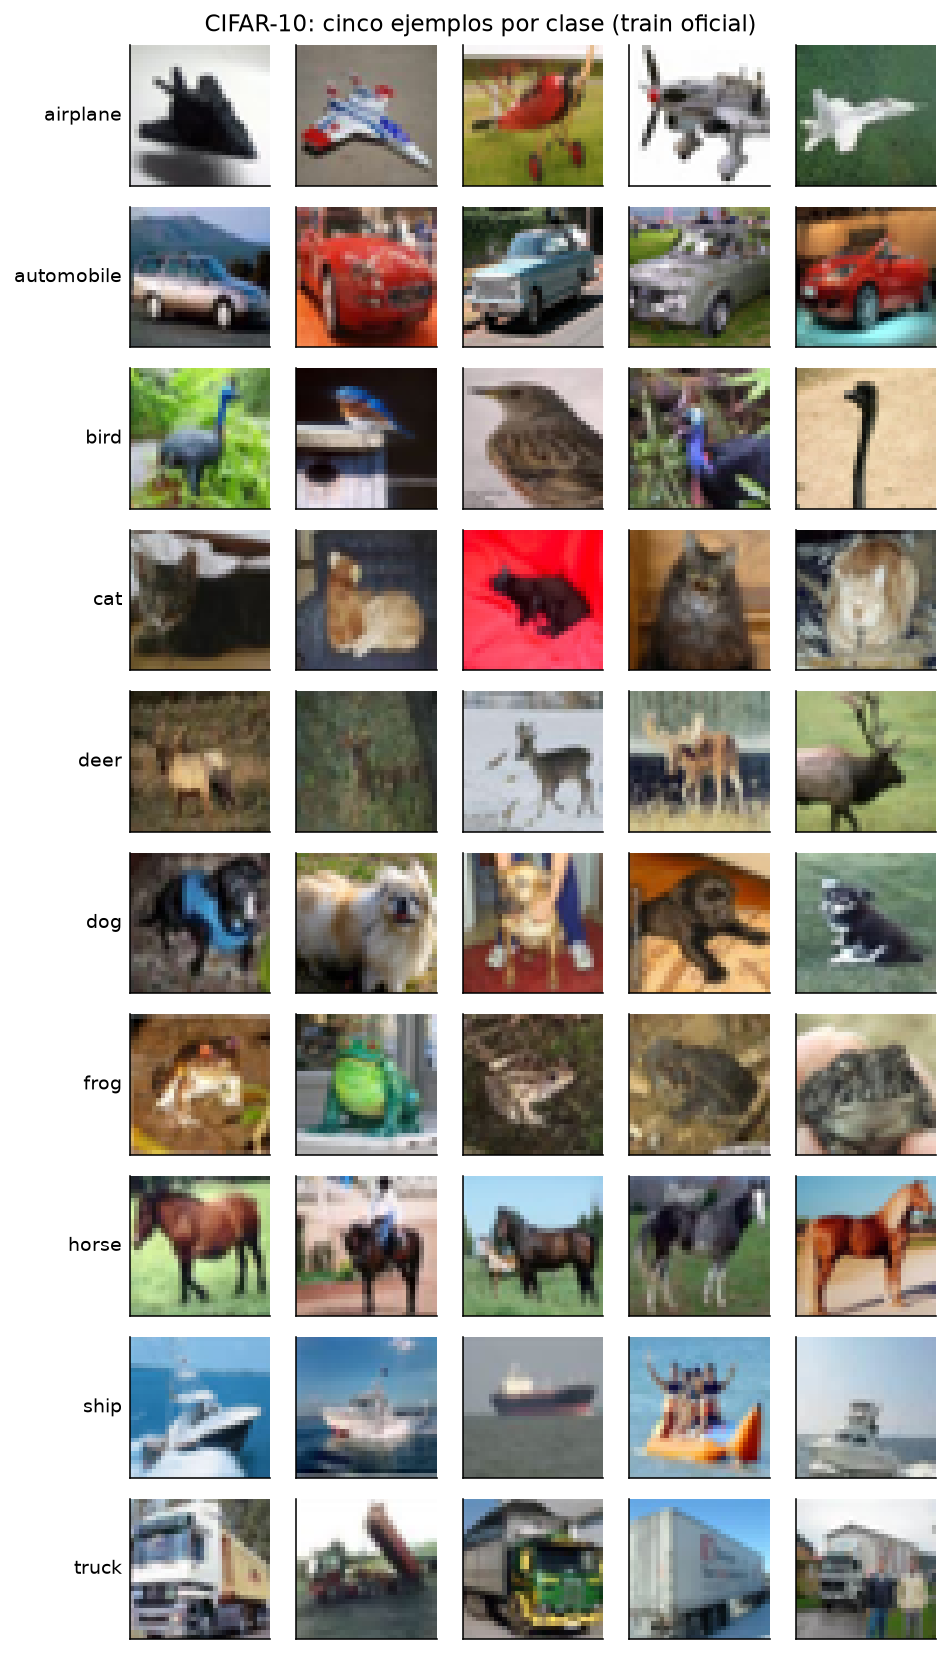

In [27]:
from IPython.display import display, Image
d = results['data']
display(pd.DataFrame({'clase':d['classes'],'train oficial':d['class_counts_official'],
                      'train': [4500]*10,'validación':[500]*10,'test':[1000]*10,'train 10%':[450]*10}))
display(pd.DataFrame({'canal':['R','G','B'],'media CIFAR-10':d['mean_official'],
                      'std CIFAR-10':d['std_official'],'media ImageNet':d['imagenet_mean'],
                      'std ImageNet':d['imagenet_std']}))
display(Image(filename=str(FIG / 'examples.png')))

Esperamos mayor dificultad en cat/dog por pelaje y postura, deer/horse por silueta,
automobile/truck por ruedas y carrocería y airplane/ship por fondos similares a esta resolución.
Estos son supuestos previos; las confusiones realmente medidas aparecen abajo.

### Pipelines torchvision equivalentes y preset oficial
El entrenamiento usa la versión vectorizada `preprocess`; los flips de VGG se fijan al construir la cache.

In [28]:
cnn_train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4, padding_mode='reflect'),
    transforms.RandomHorizontalFlip(), transforms.ToTensor(),
    transforms.Normalize(d['mean_fit'], d['std_fit'])])
cnn_eval_transform = transforms.Compose([transforms.ToTensor(),
    transforms.Normalize(d['mean_fit'], d['std_fit'])])
vgg_eval_transform = transforms.Compose([transforms.Resize((SIZE,SIZE), antialias=True),
    transforms.ToTensor(), transforms.Normalize(IM_MEAN, IM_STD)])
vgg_train_transform = transforms.Compose([transforms.Resize((SIZE,SIZE), antialias=True),
    transforms.RandomHorizontalFlip(), transforms.ToTensor(), transforms.Normalize(IM_MEAN, IM_STD)])
print('Preset original ImageNet (referencia, no se usa a 224 en estos runs):')
print(models.VGG16_Weights.IMAGENET1K_V1.transforms())

Preset original ImageNet (referencia, no se usa a 224 en estos runs):
ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


### Tabla de las nueve iteraciones: mejor epoch de validación

In [29]:
iterations = pd.read_csv(ART / 'iterations.csv')
display(iterations[['id','modelo','bloques','lr','backbone_lr','dropout','weight_decay','batch','epochs','threads']])
display(iterations[['id','mejor_epoch','val_accuracy','val_precision','val_recall','val_f1']].round(4))
display(iterations[['id','params_total','params_trainable','seconds','gpu_peak_mb','cpu_rss_mb','block4_cache']].round(2))

,id,modelo,bloques,lr,backbone_lr,dropout,weight_decay,batch,epochs,threads
0,CNN1,cnn,3 propios,0.003,NaN,0.15,0.0001,256,3,8
1,CNN2,cnn,3 propios,0.003,NaN,0.25,0.0001,256,3,8
2,CNN3,cnn,3 propios,0.001,NaN,0.35,0.0005,256,3,8
3,FE1,fe,ninguno,0.010,NaN,0.50,0.0001,512,2,8
4,FE2,fe,ninguno,0.020,NaN,0.30,0.0001,512,2,8
5,FE3,fe,ninguno,0.005,NaN,0.50,0.0005,512,2,8
6,FT1,ft,5,0.010,0.0001,0.50,0.0001,512,2,8
7,FT2,ft,4+5,0.010,0.0001,0.50,0.0001,1024,2,12
8,FT3,ft,5,0.020,0.0005,0.30,0.0001,1024,2,12


,id,mejor_epoch,val_accuracy,val_precision,val_recall,val_f1
0,CNN1,3,0.6282,0.6649,0.6282,0.6319
1,CNN2,3,0.6154,0.6423,0.6154,0.6056
2,CNN3,3,0.5706,0.5844,0.5706,0.5640
3,FE1,2,0.6654,0.6639,0.6654,0.6607
4,FE2,2,0.6800,0.6801,0.6800,0.6794
5,FE3,2,0.6614,0.6601,0.6614,0.6573
6,FT1,2,0.6804,0.6788,0.6804,0.6770
7,FT2,2,0.6782,0.6770,0.6782,0.6754
8,FT3,2,0.6962,0.6967,0.6962,0.6947


,id,params_total,params_trainable,seconds,gpu_peak_mb,cpu_rss_mb,block4_cache
0,CNN1,72954,72954,58.08,NaN,799.91,False
1,CNN2,162994,162994,117.00,NaN,838.40,False
2,CNN3,162994,162994,195.94,NaN,833.37,False
3,FE1,134301514,119586826,92.71,NaN,2690.81,False
4,FE2,134301514,119586826,91.82,NaN,2687.96,False
5,FE3,134301514,119586826,93.29,NaN,2677.78,False
6,FT1,134301514,126666250,283.75,NaN,2699.54,False
7,FT2,134301514,132566026,302.72,NaN,3148.93,False
8,FT3,134301514,126666250,208.90,NaN,2724.32,True


### Historial completo: loss y métricas de cada epoch

,iteracion,epoch,train_loss,val_loss,val_accuracy,val_precision_macro,val_recall_macro,val_f1_macro
0,CNN1,1,1.6374,1.2903,0.5250,0.5224,0.5250,0.5135
1,CNN1,2,1.3177,1.1008,0.6060,0.6091,0.6060,0.6043
2,CNN1,3,1.1895,1.0716,0.6282,0.6649,0.6282,0.6319
3,CNN2,1,1.6884,1.3631,0.5026,0.5381,0.5026,0.4874
4,CNN2,2,1.3641,1.1901,0.5712,0.5855,0.5712,0.5554
5,CNN2,3,1.2145,1.0736,0.6154,0.6423,0.6154,0.6056
6,CNN3,1,1.8113,1.4481,0.4786,0.4929,0.4786,0.4648
7,CNN3,2,1.5103,1.2990,0.5360,0.5457,0.5360,0.5298
8,CNN3,3,1.3741,1.1622,0.5706,0.5844,0.5706,0.5640
9,FE1,1,1.3004,1.0006,0.6490,0.6472,0.6490,0.6461


,iteracion,epoch,train_seconds,epoch_seconds,cumulative_seconds
0,CNN1,1,18.58,19.22,19.22
1,CNN1,2,19.35,19.95,39.17
2,CNN1,3,18.31,18.88,58.06
3,CNN2,1,36.05,37.10,37.10
4,CNN2,2,37.07,38.10,75.21
5,CNN2,3,39.65,41.77,116.98
6,CNN3,1,63.16,65.25,65.25
7,CNN3,2,63.33,65.46,130.72
8,CNN3,3,63.01,65.19,195.91
9,FE1,1,41.61,42.64,42.64


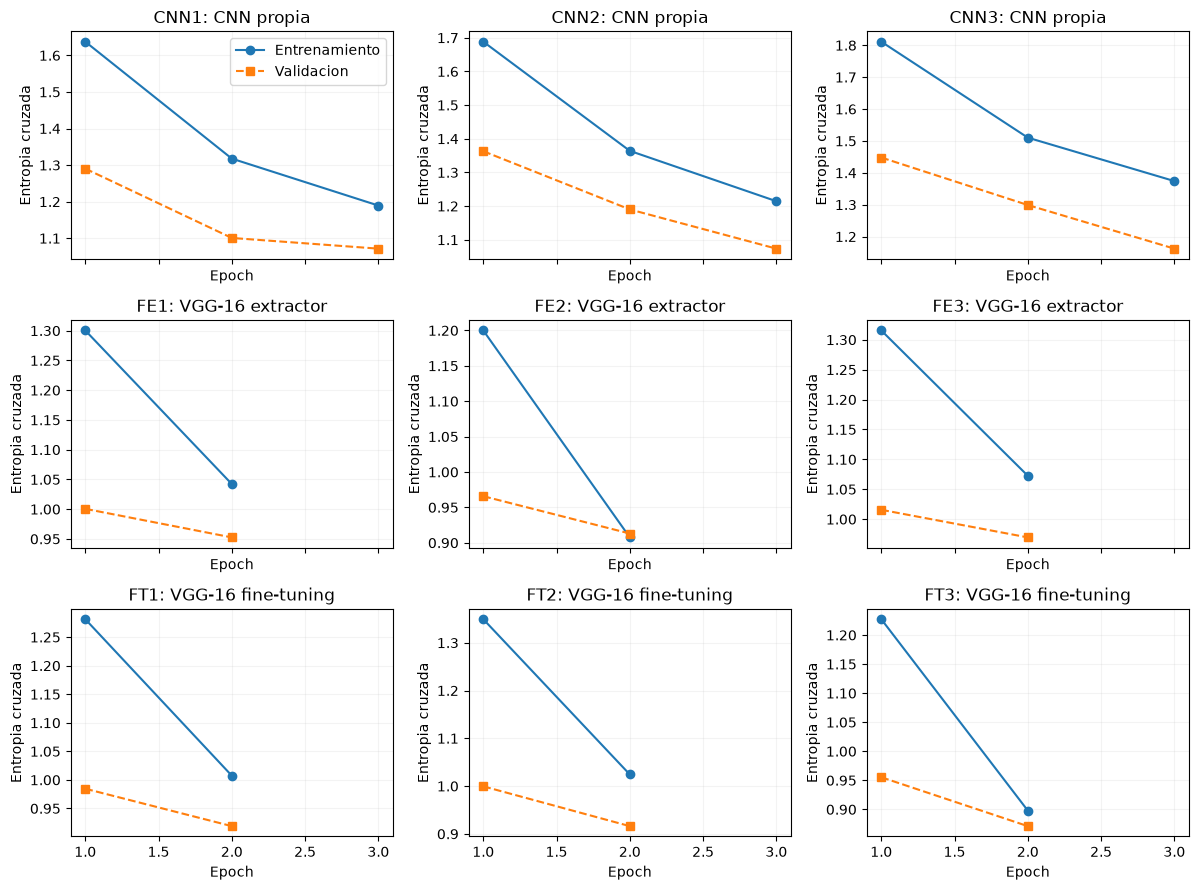

In [30]:
history = pd.concat([pd.DataFrame(r['history']).assign(iteracion=r['id']) for r in results['runs']], ignore_index=True)
display(history[['iteracion','epoch','train_loss','val_loss','val_accuracy','val_precision_macro','val_recall_macro','val_f1_macro']].round(4))
display(history[['iteracion','epoch','train_seconds','epoch_seconds','cumulative_seconds']].round(2))
display(Image(filename=str(FIG / 'loss_curves_9.png')))

### Rendimiento, recursos y reducción de datos

In [31]:
comparison = pd.read_csv(ART / 'comparison.csv')
display(comparison[['modelo','id','test_accuracy','test_precision_macro','test_recall_macro','test_f1_macro']].round(4))
display(comparison[['modelo','params_total','params_trainable','macs_inference','latency_ms','seconds_per_epoch','best_epoch','seconds_total']].round(3))
display(comparison[['modelo','cpu_peak_rss_mb','gpu_peak_mb','estimated_flops_training_nominal','test_10pct_accuracy','test_10pct_precision_macro','test_10pct_recall_macro','test_10pct_f1_macro']].round(4))
display(pd.DataFrame(results['cache']['seconds'].items(),columns=['cache','segundos']))

,modelo,id,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro
0,CNN propia,CNN1,0.6239,0.6606,0.6239,0.6284
1,VGG-16 extractor,FE2,0.6732,0.6738,0.6732,0.6727
2,VGG-16 fine-tuning,FT3,0.6869,0.6886,0.6869,0.6860


,modelo,params_total,params_trainable,macs_inference,latency_ms,seconds_per_epoch,best_epoch,seconds_total
0,CNN propia,72954,72954,9880192,0.507,18.748,3,58.083
1,VGG-16 extractor,134301514,119586826,432775168,16.748,44.238,2,91.819
2,VGG-16 fine-tuning,134301514,126666250,432775168,17.991,102.133,2,208.903


,modelo,cpu_peak_rss_mb,gpu_peak_mb,estimated_flops_training_nominal,test_10pct_accuracy,test_10pct_precision_macro,test_10pct_recall_macro,test_10pct_f1_macro
0,CNN propia,799.9062,NaN,8002955520000,0.3865,0.4143,0.3865,0.3793
1,VGG-16 extractor,2687.9648,NaN,120947834880000,0.5897,0.5916,0.5897,0.5889
2,VGG-16 fine-tuning,2724.3164,NaN,131139993600000,0.5786,0.5969,0.5786,0.5796


,cache,segundos
0,train,97.220115
1,validation,10.892299
2,test,21.768192


**Convención de costo.** MACs y FLOPs de inferencia corresponden al forward original,
sin factorización. El entrenamiento registrado usa cache y factorización exacta.
La estimación nominal es `N * E * (2*MACs_forward + 4*MACs_capas_entrenables)`;
supone backward ≈ dos forwards para las capas entrenables. Es una estimación conservadora
sin optimizador, activaciones ni validación. El cómputo ejecutado es menor con cache;
la caché se calcula una vez en train con una vista aumentada. No confundir FLOPs nominales
con operaciones realmente ejecutadas o con tiempo medido.
`gpu_peak_mb=null` significa que no hubo GPU CUDA; RSS de CPU no es memoria GPU.

### Accuracy de validación contra tiempo acumulado

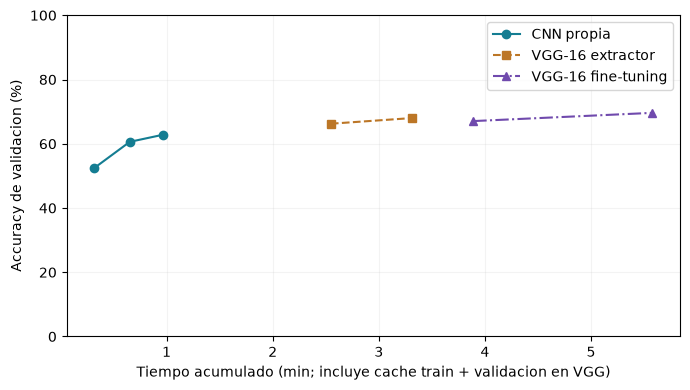

In [32]:
display(Image(filename=str(FIG / 'accuracy_time.png')))

### F1 de test contra FLOPs nominales de inferencia

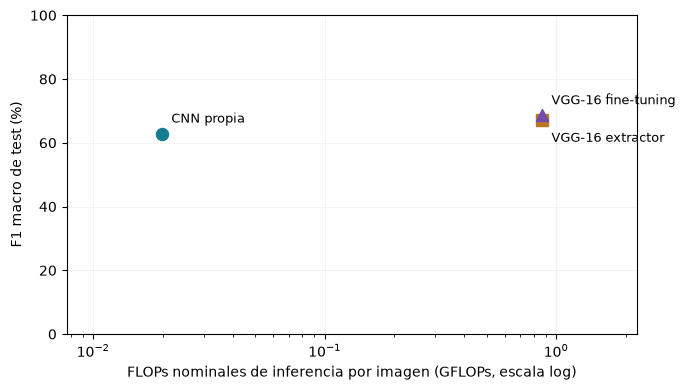

In [33]:
display(Image(filename=str(FIG / 'f1_cost.png')))

### Efecto de reducir los datos a 10%

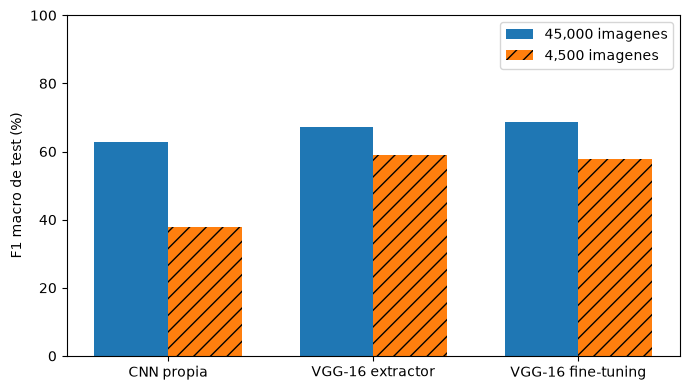

In [34]:
display(Image(filename=str(FIG / 'data_fraction.png')))

### Matrices de confusión de las configuraciones finales

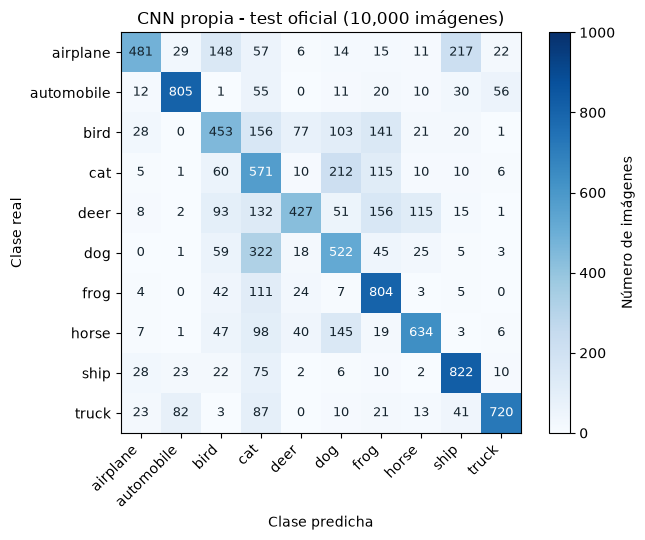

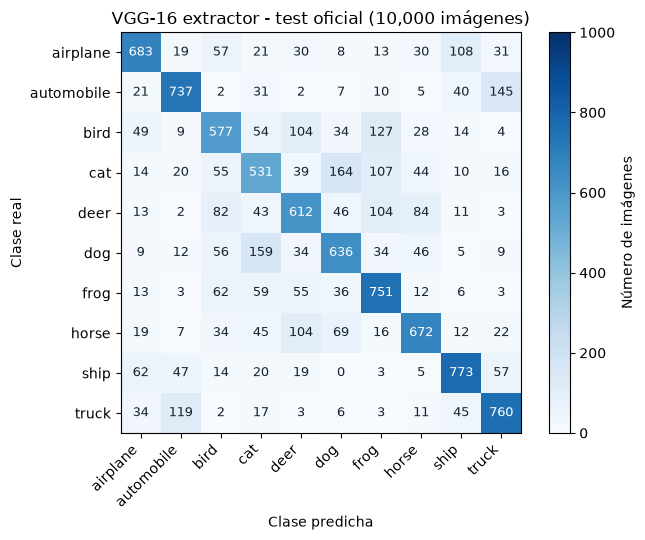

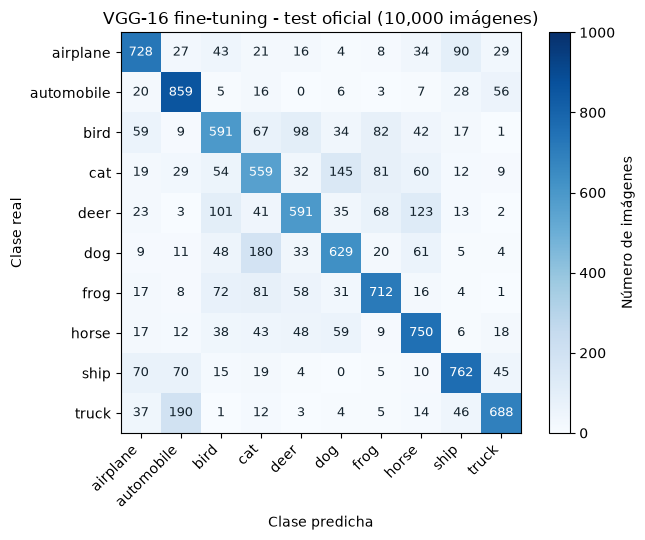

In [35]:
for model_kind in LABELS:
    display(Image(filename=str(FIG / f'confusion_{model_kind}.png')))

## 9. Discusión y conclusiones
### Desempeño y costo
VGG-16 fine-tuning obtuvo el mayor F1 macro de test (68.60%) y accuracy 68.69%. La ventaja sobre el segundo fue 1.33 puntos de F1. VGG-16 FT tiene 134.30 M parámetros frente a 0.073 M de la CNN y 43.8 veces sus FLOPs de inferencia. El costo adicional se justifica si se prioriza ese desempeño; una única semilla y dos o tres épocas limitan la fuerza de la comparación.

### Relación entre desempeño y recursos
La CNN tiene menor costo de inferencia, almacenamiento y parámetros; ofrece la opción más económica. La gráfica F1/costo permite decidir si la ganancia observada de VGG compensa el salto de cómputo. La gráfica de tiempo incorpora el costo inicial de cache train/validación: ignorarlo favorecería artificialmente al transfer learning. No se presenta un cociente arbitrario F1/FLOPs como una medida universal de calidad.

### Transferencia y redimensionamiento
Las convoluciones preentrenadas detectan bordes, texturas y formas reutilizables en imágenes de animales y vehículos. Los bloques superiores son más específicos a ImageNet. El resize aproxima la escala esperada pero solo interpola los 1,024 píxeles originales. Pasar a 224 produce 50,176 píxeles por canal, 49 veces más, y aproximadamente ese crecimiento en costo convolucional, sin multiplicar en la misma proporción el costo del clasificador. 32×32 reduce cómputo pero puede perjudicar desempeño.

### Bloques, learning rate y sobreajuste
FT1 B5, LR backbone 0.0001: F1 val 67.70%; FT2 B4+5, LR backbone 0.0001: F1 val 67.54%; FT3 B5, LR backbone 0.0005: F1 val 69.47%. Ganó FT3. Las nueve curvas reducen ambas pérdidas entre primera y última epoch; no se observa esa señal temprana de sobreajuste. La diferencia final loss validación - entrenamiento fue -0.027; dropout y augmentation hacen que esas pérdidas no sean estrictamente comparables. FT2/FT3 usan batch 1024 frente a 512 de FT1; FT3 cambia también dropout, así que no se aíslan completamente estos efectos. Dos épocas VGG no aseguran convergencia ni descartan overfitting posterior. No se comprobó catastrophic forgetting: requiere medir retención de la tarea original o comparar representaciones.

### Cantidad de datos
Cambios de F1 (100% menos 10%): CNN propia +24.91 puntos; VGG-16 extractor +8.39 puntos; VGG-16 fine-tuning +10.64 puntos. CNN propia presenta la mayor caída en esta ejecución. Una representación preentrenada suele ser útil con pocos datos y congelar limita grados de libertad; FT requiere LR bajo y control de validación. Aquí conservar épocas también reduce pasos, así que estas diferencias no pueden atribuirse exclusivamente al tamaño de la muestra.

### Matrices de confusión
CNN propia: cat/dog: 534; airplane/ship: 245; cat/frog: 226. VGG-16 extractor: cat/dog: 323; automobile/truck: 264; bird/frog: 189. VGG-16 fine-tuning: cat/dog: 325; automobile/truck: 246; bird/deer: 199. Pares compartidos entre los tres top-3: cat/dog. Las frecuencias difieren por modelo; filas reales, columnas predichas y 1,000 ejemplos por fila.

### Despliegue
Para un servidor con GPU priorizaríamos VGG-16 fine-tuning si la calidad observada es el objetivo; validaríamos primero su latencia y memoria en la GPU real, pues aquí solo se midió CPU. Para móvil elegiríamos la CNN propia por menor número de parámetros y operaciones. Como alternativa preentrenada consideraríamos MobileNetV3 Small, diseñada con bloques ligeros; su calidad y latencia en este dataset necesitarían un experimento adicional.

## 10. Comprobaciones de integridad

In [36]:
from sklearn.metrics import precision_recall_fscore_support, accuracy_score
split = np.load(ART / 'split_indices.npz')
assert len(set(split['train']) & set(split['validation'])) == 0
assert set(split['reduced']).issubset(set(split['train']))
for collection in [results['finals'], results['reduced_tests']]:
    for k, e in collection.items():
        preds = np.load(ART / 'evaluations' / f"{e['id']}_predictions.npz")
        y_true, y_pred = preds['y_true'], preds['y_pred']
        assert len(y_true) == 10000
        assert np.asarray(e['confusion_matrix']).sum() == 10000
        assert np.all(np.asarray(e['confusion_matrix']).sum(axis=1) == 1000)
        p,r,f,_ = precision_recall_fscore_support(y_true,y_pred,average='macro',zero_division=0)
        assert abs(f-e['test']['f1_macro']) < 1e-12
        assert abs(accuracy_score(y_true,y_pred)-e['test']['accuracy']) < 1e-12
print('9 configuraciones, 6 evaluaciones de test, métricas y splits verificados.')

9 configuraciones, 6 evaluaciones de test, métricas y splits verificados.


## Referencias
- [CIFAR-10, Krizhevsky (2009)](https://www.cs.toronto.edu/~kriz/cifar.html)
- [Torchvision: VGG-16 y pesos](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.vgg16.html)
- [PyTorch: transfer learning](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html)
- [PyTorch: autograd y requires_grad](https://docs.pytorch.org/docs/2.14/notes/autograd.html)
- [PyTorch: optimizadores y param_groups](https://docs.pytorch.org/docs/2.14/optim.html)
- [PyTorch: Module.train y Module.eval](https://docs.pytorch.org/docs/2.14/generated/torch.nn.Module.html)
- [THOP: contador de MACs](https://github.com/Lyken17/pytorch-OpCounter)
- [PyTorch: memoria CUDA](https://docs.pytorch.org/docs/2.14/generated/torch.cuda.max_memory_allocated.html)
- [PyTorch: sincronizacion CUDA](https://docs.pytorch.org/docs/2.14/generated/torch.cuda.synchronize.html)
- [Torchvision: MobileNet V3 Small](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.mobilenet_v3_small.html)

Repositorio: [https://github.com/iancumes/Laboratorio6DeepLearning](https://github.com/iancumes/Laboratorio6DeepLearning)